In [ ]:
# ================================================================
# PHASE 4A — CELL 1
# END-TO-END ERROR PROPAGATION ANALYSIS
# SETUP
# ================================================================

from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path

import json
import numpy as np
import pandas as pd

print("=" * 80)
print("PHASE 4A — END-TO-END ERROR PROPAGATION ANALYSIS")
print("=" * 80)

print("\nPurpose:")
print(
    "Analyze associations between upstream LV-analysis errors and "
    "downstream EF / classification errors using frozen outputs."
)

print("\nProtocol:")
print(" • No model training")
print(" • No model selection")
print(" • No threshold tuning")
print(" • No calibration")
print(" • No modification of Phase 1–3 frozen outputs")
print(" • Locked evaluation results are used descriptively")

print("\n✓ Setup complete.")

Mounted at /content/drive
PHASE 4A — END-TO-END ERROR PROPAGATION ANALYSIS

Purpose:
Analyze associations between upstream LV-analysis errors and downstream EF / classification errors using frozen outputs.

Protocol:
 • No model training
 • No model selection
 • No threshold tuning
 • No calibration
 • No modification of Phase 1–3 frozen outputs
 • Locked evaluation results are used descriptively

✓ Setup complete.


In [ ]:
# ================================================================
# PHASE 4A — CELL 2
# DEFINE PROJECT AND FROZEN ARTIFACT PATHS
# ================================================================

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/CAMUS_FINAL"
)

PHASE1E_DIR = (
    PROJECT_ROOT
    / "phase1_segmentation"
    / "phase1E_final_validation"
)

PHASE2B_DIR = (
    PROJECT_ROOT
    / "phase2_quantitative"
    / "phase2B_final_evaluation"
)

PHASE3D_DIR = (
    PROJECT_ROOT
    / "phase3_classification"
    / "phase3D_final_evaluation"
)

PHASE4_ROOT = (
    PROJECT_ROOT
    / "phase4_robustness"
)

PHASE4A_DIR = (
    PHASE4_ROOT
    / "phase4A_error_propagation"
)

PHASE4A_TABLES_DIR = (
    PHASE4A_DIR
    / "tables"
)

PHASE4A_FIGURES_DIR = (
    PHASE4A_DIR
    / "figures"
)

PHASE4A_CONFIGS_DIR = (
    PHASE4A_DIR
    / "configs"
)


# ---------------------------------------------------------------
# CREATE ONLY NEW PHASE 4 DIRECTORIES
# ---------------------------------------------------------------

for directory in [
    PHASE4A_DIR,
    PHASE4A_TABLES_DIR,
    PHASE4A_FIGURES_DIR,
    PHASE4A_CONFIGS_DIR
]:
    directory.mkdir(
        parents=True,
        exist_ok=True
    )


# ---------------------------------------------------------------
# VERIFY FROZEN PHASE DIRECTORIES
# ---------------------------------------------------------------

assert PROJECT_ROOT.exists(), (
    f"Project root not found:\n{PROJECT_ROOT}"
)

assert PHASE1E_DIR.exists(), (
    f"Phase 1E directory not found:\n{PHASE1E_DIR}"
)

assert PHASE2B_DIR.exists(), (
    f"Phase 2B directory not found:\n{PHASE2B_DIR}"
)

assert PHASE3D_DIR.exists(), (
    f"Phase 3D directory not found:\n{PHASE3D_DIR}"
)


print("=" * 80)
print("PHASE 4A DIRECTORY SETUP")
print("=" * 80)

print("\nFrozen inputs:")
print("Phase 1E :", PHASE1E_DIR)
print("Phase 2B :", PHASE2B_DIR)
print("Phase 3D :", PHASE3D_DIR)

print("\nNew output directory:")
print(PHASE4A_DIR)

print("\n✓ Required frozen phase directories found.")
print("✓ Phase 4A output directories created.")

PHASE 4A DIRECTORY SETUP

Frozen inputs:
Phase 1E : /content/drive/MyDrive/CAMUS_FINAL/phase1_segmentation/phase1E_final_validation
Phase 2B : /content/drive/MyDrive/CAMUS_FINAL/phase2_quantitative/phase2B_final_evaluation
Phase 3D : /content/drive/MyDrive/CAMUS_FINAL/phase3_classification/phase3D_final_evaluation

New output directory:
/content/drive/MyDrive/CAMUS_FINAL/phase4_robustness/phase4A_error_propagation

✓ Required frozen phase directories found.
✓ Phase 4A output directories created.


In [ ]:
# ================================================================
# PHASE 4A — CELL 3
# INVENTORY FROZEN ARTIFACTS
# ================================================================

def inventory_directory(directory, label):

    print("\n" + "=" * 80)
    print(label)
    print("=" * 80)

    files = sorted([
        path
        for path in directory.rglob("*")
        if path.is_file()
    ])

    print(
        f"\nFiles found: {len(files)}"
    )

    for path in files:

        relative_path = (
            path.relative_to(directory)
        )

        size_kb = (
            path.stat().st_size / 1024
        )

        print(
            f" • {str(relative_path):<65} "
            f"{size_kb:>10.2f} KB"
        )

    return files


phase1e_files = inventory_directory(
    PHASE1E_DIR,
    "PHASE 1E — FROZEN SEGMENTATION ARTIFACTS"
)

phase2b_files = inventory_directory(
    PHASE2B_DIR,
    "PHASE 2B — FROZEN QUANTITATIVE ARTIFACTS"
)

phase3d_files = inventory_directory(
    PHASE3D_DIR,
    "PHASE 3D — FROZEN CLASSIFICATION ARTIFACTS"
)


print(
    "\n✓ Frozen artifact inventory complete."
)


PHASE 1E — FROZEN SEGMENTATION ARTIFACTS

Files found: 12
 • configs/phase1E_evaluation_protocol.json                                1.86 KB
 • configs/phase1E_final_validation_record.json                            2.96 KB
 • plots/test_area_error_ED_vs_ES.png                                     61.26 KB
 • plots/test_dice_ED_vs_ES.png                                           56.39 KB
 • plots/test_signed_area_error_ED_vs_ES.png                              67.38 KB
 • tables/final_test_distribution_summary.csv                              0.91 KB
 • tables/final_test_frame_metrics.csv                                    16.57 KB
 • tables/final_test_patient_level_metrics.csv                            11.60 KB
 • tables/final_test_summary.csv                                           0.59 KB
 • tables/validation_vs_final_test.csv                                     0.61 KB
 • tables/worst_10_area_error_cases.csv                                    1.82 KB
 • tables/worst_10_dice_case

In [ ]:
# ================================================================
# PHASE 4A — CELL 4
# INSPECT SAVED CSV TABLE SCHEMAS
# ================================================================

def inspect_csv_files(files, phase_label):

    csv_files = [
        path
        for path in files
        if path.suffix.lower() == ".csv"
    ]


    print("\n" + "=" * 80)
    print(f"{phase_label} — CSV SCHEMA INSPECTION")
    print("=" * 80)


    if len(csv_files) == 0:

        print(
            "\nNo CSV files found."
        )

        return


    for csv_path in csv_files:

        print(
            "\n" + "-" * 80
        )

        print(
            "FILE:",
            csv_path.name
        )

        print(
            "PATH:",
            csv_path
        )


        try:

            temp_df = pd.read_csv(
                csv_path
            )


            print(
                "Shape:",
                temp_df.shape
            )


            print(
                "\nColumns:"
            )


            for index, column in enumerate(
                temp_df.columns,
                start=1
            ):

                print(
                    f" {index:>2}. {column}"
                )


            print(
                "\nFirst 2 rows:"
            )


            display(
                temp_df.head(2)
            )


        except Exception as error:

            print(
                "\nCould not read CSV:"
            )

            print(
                error
            )


inspect_csv_files(
    phase1e_files,
    "PHASE 1E"
)

inspect_csv_files(
    phase2b_files,
    "PHASE 2B"
)

inspect_csv_files(
    phase3d_files,
    "PHASE 3D"
)


print(
    "\n" + "=" * 80
)

print(
    "✓ CSV schema inspection complete."
)

print(
    "=" * 80
)


PHASE 1E — CSV SCHEMA INSPECTION

--------------------------------------------------------------------------------
FILE: final_test_distribution_summary.csv
PATH: /content/drive/MyDrive/CAMUS_FINAL/phase1_segmentation/phase1E_final_validation/tables/final_test_distribution_summary.csv
Shape: (3, 17)

Columns:
  1. phase
  2. n_frames
  3. dice_mean
  4. dice_std
  5. dice_median
  6. dice_q25
  7. dice_q75
  8. dice_min
  9. dice_max
 10. frames_dice_below_0.90
 11. frames_dice_below_0.85
 12. area_MAE_mean_pct
 13. area_MAE_median_pct
 14. area_MAE_q75_pct
 15. area_MAE_max_pct
 16. frames_area_error_above_10pct
 17. frames_area_error_above_20pct

First 2 rows:


,phase,n_frames,dice_mean,dice_std,dice_median,dice_q25,dice_q75,dice_min,dice_max,frames_dice_below_0.90,frames_dice_below_0.85,area_MAE_mean_pct,area_MAE_median_pct,area_MAE_q75_pct,area_MAE_max_pct,frames_area_error_above_10pct,frames_area_error_above_20pct
0,Overall,100,0.929248,0.037546,0.939624,0.913532,0.955047,0.716995,0.97629,15,2,8.182060,6.023609,11.992609,42.148518,33,6
1,ED,50,0.939564,0.025293,0.945730,0.925826,0.957908,0.867799,0.97629,4,0,6.881699,5.597632,9.630906,20.090516,11,1



--------------------------------------------------------------------------------
FILE: final_test_frame_metrics.csv
PATH: /content/drive/MyDrive/CAMUS_FINAL/phase1_segmentation/phase1E_final_validation/tables/final_test_frame_metrics.csv
Shape: (100, 12)

Columns:
  1. patient_id
  2. phase
  3. dice
  4. iou
  5. precision
  6. recall
  7. hd95_pixels
  8. normalized_hd95
  9. gt_area_pixels
 10. pred_area_pixels
 11. signed_area_error_pct
 12. abs_area_error_pct

First 2 rows:


,patient_id,phase,dice,iou,precision,recall,hd95_pixels,normalized_hd95,gt_area_pixels,pred_area_pixels,signed_area_error_pct,abs_area_error_pct
0,patient0173,ED,0.958785,0.920833,0.983730,0.935074,6.0,0.023438,6854,6515,-4.946017,4.946017
1,patient0173,ES,0.956244,0.916157,0.985201,0.928941,3.0,0.011719,3870,3649,-5.710594,5.710594



--------------------------------------------------------------------------------
FILE: final_test_patient_level_metrics.csv
PATH: /content/drive/MyDrive/CAMUS_FINAL/phase1_segmentation/phase1E_final_validation/tables/final_test_patient_level_metrics.csv
Shape: (50, 13)

Columns:
  1. patient_id
  2. ED_dice
  3. ED_iou
  4. ED_normalized_hd95
  5. ED_signed_area_error_pct
  6. ED_abs_area_error_pct
  7. ES_dice
  8. ES_iou
  9. ES_normalized_hd95
 10. ES_signed_area_error_pct
 11. ES_abs_area_error_pct
 12. mean_ED_ES_dice
 13. mean_ED_ES_area_MAE_pct

First 2 rows:


...


--------------------------------------------------------------------------------
FILE: phase3D_final_patient_predictions.csv
PATH: /content/drive/MyDrive/CAMUS_FINAL/phase3_classification/phase3D_final_evaluation/tables/phase3D_final_patient_predictions.csv
Shape: (50, 17)

Columns:
  1. patient_id
  2. reference_EF_pct
  3. reference_EF_class
  4. PRED_ED_area_mm2
  5. PRED_ES_area_mm2
  6. PRED_ED_length_mm
  7. PRED_ES_length_mm
  8. PRED_EDV_ml
  9. PRED_ESV_ml
 10. PRED_SV_ml
 11. PRED_EF_pct
 12. learned_prediction
 13. correct
 14. prob_Higher_EF
 15. prob_Intermediate_EF
 16. prob_Lower_EF
 17. absolute_EF_error_pp

First 2 rows:


,patient_id,reference_EF_pct,reference_EF_class,PRED_ED_area_mm2,PRED_ES_area_mm2,PRED_ED_length_mm,PRED_ES_length_mm,PRED_EDV_ml,PRED_ESV_ml,PRED_SV_ml,PRED_EF_pct,learned_prediction,correct,prob_Higher_EF,prob_Intermediate_EF,prob_Lower_EF,absolute_EF_error_pp
0,patient0004,56.0,Higher_EF,2885.532376,1511.850467,77.877153,59.824512,90.752938,32.430778,58.322160,64.264762,Higher_EF,True,0.805372,0.185380,0.009248,8.264762
1,patient0013,35.0,Lower_EF,2836.311585,2023.798654,90.840418,73.953378,75.170530,47.010562,28.159968,37.461446,Lower_EF,True,0.013721,0.319127,0.667152,2.461446



--------------------------------------------------------------------------------
FILE: phase3D_final_per_class_metrics.csv
PATH: /content/drive/MyDrive/CAMUS_FINAL/phase3_classification/phase3D_final_evaluation/tables/phase3D_final_per_class_metrics.csv
Shape: (3, 5)

Columns:
  1. class
  2. precision
  3. recall
  4. f1
  5. support

First 2 rows:


,class,precision,recall,f1,support
0,Lower_EF,0.684211,0.812500,0.742857,16
1,Intermediate_EF,0.500000,0.357143,0.416667,14



✓ CSV schema inspection complete.


In [ ]:
# ================================================================
# PHASE 4A — CELL 5
# LOAD CANONICAL PATIENT-LEVEL FROZEN OUTPUTS
# ================================================================

PHASE1_PATIENT_PATH = (
    PHASE1E_DIR
    / "tables"
    / "final_test_patient_level_metrics.csv"
)

PHASE2_PATIENT_PATH = (
    PHASE2B_DIR
    / "tables"
    / "final_test_patient_level_errors.csv"
)

PHASE3_PATIENT_PATH = (
    PHASE3D_DIR
    / "tables"
    / "phase3D_final_patient_predictions.csv"
)


for path in [
    PHASE1_PATIENT_PATH,
    PHASE2_PATIENT_PATH,
    PHASE3_PATIENT_PATH
]:
    assert path.exists(), (
        f"Required frozen table not found:\n{path}"
    )


phase1_patient_df = pd.read_csv(
    PHASE1_PATIENT_PATH
)

phase2_patient_df = pd.read_csv(
    PHASE2_PATIENT_PATH
)

phase3_patient_df = pd.read_csv(
    PHASE3_PATIENT_PATH
)


print("=" * 80)
print("FROZEN PATIENT-LEVEL TABLES LOADED")
print("=" * 80)

print(
    "\nPhase 1E:",
    phase1_patient_df.shape
)

print(
    "Phase 2B:",
    phase2_patient_df.shape
)

print(
    "Phase 3D:",
    phase3_patient_df.shape
)


assert phase1_patient_df.shape[0] == 50
assert phase2_patient_df.shape[0] == 50
assert phase3_patient_df.shape[0] == 50


print(
    "\n✓ All three tables contain 50 patients."
)

FROZEN PATIENT-LEVEL TABLES LOADED

Phase 1E: (50, 13)
Phase 2B: (50, 27)
Phase 3D: (50, 17)

✓ All three tables contain 50 patients.


In [ ]:
# ================================================================
# PHASE 4A — CELL 6
# VERIFY PATIENT ALIGNMENT ACROSS PHASES
# ================================================================

phase1_ids = set(
    phase1_patient_df["patient_id"]
)

phase2_ids = set(
    phase2_patient_df["patient_id"]
)

phase3_ids = set(
    phase3_patient_df["patient_id"]
)


print("=" * 80)
print("PATIENT ALIGNMENT CHECK")
print("=" * 80)


print(
    "\nUnique Phase 1E patients:",
    len(phase1_ids)
)

print(
    "Unique Phase 2B patients:",
    len(phase2_ids)
)

print(
    "Unique Phase 3D patients:",
    len(phase3_ids)
)


print(
    "\nPhase 1E only:",
    sorted(
        phase1_ids - phase2_ids - phase3_ids
    )
)

print(
    "Phase 2B only:",
    sorted(
        phase2_ids - phase1_ids - phase3_ids
    )
)

print(
    "Phase 3D only:",
    sorted(
        phase3_ids - phase1_ids - phase2_ids
    )
)


common_ids = (
    phase1_ids
    & phase2_ids
    & phase3_ids
)


assert len(common_ids) == 50, (
    "The three frozen phases do not contain "
    "the exact same 50 patients."
)


assert (
    phase1_patient_df["patient_id"].nunique()
    == 50
)

assert (
    phase2_patient_df["patient_id"].nunique()
    == 50
)

assert (
    phase3_patient_df["patient_id"].nunique()
    == 50
)


print(
    "\n✓ Exact same 50 patients confirmed."
)

print(
    "✓ No duplicate patient IDs."
)

print(
    "✓ Safe to construct Phase 4A canonical table."
)

PATIENT ALIGNMENT CHECK

Unique Phase 1E patients: 50
Unique Phase 2B patients: 50
Unique Phase 3D patients: 50

Phase 1E only: []
Phase 2B only: []
Phase 3D only: []

✓ Exact same 50 patients confirmed.
✓ No duplicate patient IDs.
✓ Safe to construct Phase 4A canonical table.


In [ ]:
# ================================================================
# PHASE 4A — CELL 7
# BUILD CANONICAL END-TO-END PATIENT TABLE
# ================================================================

# ---------------------------------------------------------------
# PHASE 1 — SEGMENTATION INFORMATION
# ---------------------------------------------------------------

phase1_keep = phase1_patient_df[[
    "patient_id",

    "ED_dice",
    "ED_iou",
    "ED_normalized_hd95",
    "ED_signed_area_error_pct",
    "ED_abs_area_error_pct",

    "ES_dice",
    "ES_iou",
    "ES_normalized_hd95",
    "ES_signed_area_error_pct",
    "ES_abs_area_error_pct",

    "mean_ED_ES_dice",
    "mean_ED_ES_area_MAE_pct"
]].copy()


# ---------------------------------------------------------------
# PHASE 2 — QUANTITATIVE INFORMATION
# ---------------------------------------------------------------

phase2_keep = phase2_patient_df.copy()


# ---------------------------------------------------------------
# PHASE 3 — CLASSIFICATION INFORMATION ONLY
# ---------------------------------------------------------------

phase3_keep = phase3_patient_df[[
    "patient_id",

    "reference_EF_class",
    "learned_prediction",
    "correct",

    "prob_Higher_EF",
    "prob_Intermediate_EF",
    "prob_Lower_EF"
]].copy()


# ---------------------------------------------------------------
# MERGE
# ---------------------------------------------------------------

phase4A_df = (
    phase1_keep
    .merge(
        phase2_keep,
        on="patient_id",
        how="inner",
        validate="one_to_one"
    )
    .merge(
        phase3_keep,
        on="patient_id",
        how="inner",
        validate="one_to_one"
    )
    .sort_values(
        "patient_id"
    )
    .reset_index(
        drop=True
    )
)


assert len(
    phase4A_df
) == 50


print("=" * 80)
print("PHASE 4A CANONICAL TABLE")
print("=" * 80)

print(
    "\nShape:",
    phase4A_df.shape
)

print(
    "Patients:",
    phase4A_df[
        "patient_id"
    ].nunique()
)

print(
    "\nColumns:",
    len(
        phase4A_df.columns
    )
)


for index, column in enumerate(
    phase4A_df.columns,
    start=1
):

    print(
        f"{index:>2}. {column}"
    )


print(
    "\n✓ Canonical Phase 4A table constructed."
)

PHASE 4A CANONICAL TABLE

Shape: (50, 45)
Patients: 50

Columns: 45
 1. patient_id
 2. ED_dice
 3. ED_iou
 4. ED_normalized_hd95
 5. ED_signed_area_error_pct
 6. ED_abs_area_error_pct
 7. ES_dice
 8. ES_iou
 9. ES_normalized_hd95
10. ES_signed_area_error_pct
11. ES_abs_area_error_pct
12. mean_ED_ES_dice
13. mean_ED_ES_area_MAE_pct
14. reference_EF_pct
15. image_quality
16. age
17. sex
18. ED_GT_area_mm2
19. ED_PRED_area_mm2
20. ED_GT_length_mm
21. ED_PRED_length_mm
22. ED_GT_volume_ml
23. ED_PRED_volume_ml
24. ES_GT_area_mm2
25. ES_PRED_area_mm2
26. ES_GT_length_mm
27. ES_PRED_length_mm
28. ES_GT_volume_ml
29. ES_PRED_volume_ml
30. GT_SV_ml
31. GT_EF_pct
32. PRED_SV_ml
33. PRED_EF_pct
34. GT_to_PRED_EF_error_pp
35. GT_to_PRED_EF_abs_error_pp
36. Reference_to_PRED_EF_error_pp
37. Reference_to_PRED_EF_abs_error_pp
38. ED_area_relative_error_pct
39. ES_area_relative_error_pct
40. reference_EF_class
41. learned_prediction
42. correct
43. prob_Higher_EF
44. prob_Intermediate_EF
45. prob_Low

In [ ]:
# ================================================================
# PHASE 4A — CELL 8
# DERIVE ERROR-PROPAGATION VARIABLES
# ================================================================

phase4A_df = phase4A_df.copy()


# ---------------------------------------------------------------
# LENGTH ERRORS
# ---------------------------------------------------------------

phase4A_df[
    "ED_length_abs_error_mm"
] = np.abs(
    phase4A_df["ED_PRED_length_mm"]
    -
    phase4A_df["ED_GT_length_mm"]
)


phase4A_df[
    "ES_length_abs_error_mm"
] = np.abs(
    phase4A_df["ES_PRED_length_mm"]
    -
    phase4A_df["ES_GT_length_mm"]
)


# ---------------------------------------------------------------
# VOLUME ERRORS
# ---------------------------------------------------------------

phase4A_df[
    "EDV_abs_error_ml"
] = np.abs(
    phase4A_df["ED_PRED_volume_ml"]
    -
    phase4A_df["ED_GT_volume_ml"]
)


phase4A_df[
    "ESV_abs_error_ml"
] = np.abs(
    phase4A_df["ES_PRED_volume_ml"]
    -
    phase4A_df["ES_GT_volume_ml"]
)


phase4A_df[
    "SV_abs_error_ml"
] = np.abs(
    phase4A_df["PRED_SV_ml"]
    -
    phase4A_df["GT_SV_ml"]
)


# ---------------------------------------------------------------
# RELATIVE VOLUME ERRORS
# ---------------------------------------------------------------

phase4A_df[
    "EDV_abs_relative_error_pct"
] = (
    phase4A_df[
        "EDV_abs_error_ml"
    ]
    /
    phase4A_df[
        "ED_GT_volume_ml"
    ]
    * 100.0
)


phase4A_df[
    "ESV_abs_relative_error_pct"
] = (
    phase4A_df[
        "ESV_abs_error_ml"
    ]
    /
    phase4A_df[
        "ES_GT_volume_ml"
    ]
    * 100.0
)


# ---------------------------------------------------------------
# AREA ERROR MAGNITUDES
# Phase 2 stored signed relative errors.
# ---------------------------------------------------------------

phase4A_df[
    "ED_area_abs_relative_error_pct"
] = np.abs(
    phase4A_df[
        "ED_area_relative_error_pct"
    ]
)


phase4A_df[
    "ES_area_abs_relative_error_pct"
] = np.abs(
    phase4A_df[
        "ES_area_relative_error_pct"
    ]
)


# ---------------------------------------------------------------
# EF ERROR DECOMPOSITION
# ---------------------------------------------------------------

phase4A_df[
    "geometry_reference_EF_error_pp"
] = (
    phase4A_df["GT_EF_pct"]
    -
    phase4A_df["reference_EF_pct"]
)


phase4A_df[
    "geometry_reference_EF_abs_error_pp"
] = np.abs(
    phase4A_df[
        "geometry_reference_EF_error_pp"
    ]
)


phase4A_df[
    "segmentation_induced_EF_abs_error_pp"
] = phase4A_df[
    "GT_to_PRED_EF_abs_error_pp"
]


phase4A_df[
    "end_to_end_EF_abs_error_pp"
] = phase4A_df[
    "Reference_to_PRED_EF_abs_error_pp"
]


# ---------------------------------------------------------------
# CLASSIFICATION ERROR
# ---------------------------------------------------------------

phase4A_df[
    "classification_error"
] = (
    ~phase4A_df[
        "correct"
    ].astype(bool)
).astype(int)


# ---------------------------------------------------------------
# MODEL CONFIDENCE
#
# Descriptive score only.
# The logistic-regression probabilities were NOT separately
# calibrated, so do not call this calibrated certainty.
# ---------------------------------------------------------------

probability_columns = [
    "prob_Higher_EF",
    "prob_Intermediate_EF",
    "prob_Lower_EF"
]


phase4A_df[
    "model_confidence"
] = phase4A_df[
    probability_columns
].max(
    axis=1
)


sorted_probabilities = np.sort(
    phase4A_df[
        probability_columns
    ].to_numpy(),
    axis=1
)


phase4A_df[
    "confidence_margin"
] = (
    sorted_probabilities[:, -1]
    -
    sorted_probabilities[:, -2]
)


# ---------------------------------------------------------------
# SANITY CHECKS
# ---------------------------------------------------------------

assert phase4A_df[
    "classification_error"
].sum() == 15, (
    "Expected 15 Phase 3D misclassifications."
)


assert np.all(
    phase4A_df[
        "model_confidence"
    ].between(
        0,
        1
    )
)


print("=" * 80)
print("DERIVED ERROR-PROPAGATION VARIABLES")
print("=" * 80)

print(
    "\nClassification correct:",
    int(
        (
            phase4A_df[
                "classification_error"
            ] == 0
        ).sum()
    )
)

print(
    "Classification incorrect:",
    int(
        phase4A_df[
            "classification_error"
        ].sum()
    )
)


print(
    "\nMean segmentation-induced EF absolute error:",
    f"{phase4A_df['segmentation_induced_EF_abs_error_pp'].mean():.4f} pp"
)

print(
    "Mean geometry/reference EF absolute disagreement:",
    f"{phase4A_df['geometry_reference_EF_abs_error_pp'].mean():.4f} pp"
)

print(
    "Mean end-to-end EF absolute error:",
    f"{phase4A_df['end_to_end_EF_abs_error_pp'].mean():.4f} pp"
)

print(
    "\nMean model confidence:",
    f"{phase4A_df['model_confidence'].mean():.4f}"
)

print(
    "Mean confidence margin:",
    f"{phase4A_df['confidence_margin'].mean():.4f}"
)


print(
    "\n✓ Error-propagation variables created."
)

DERIVED ERROR-PROPAGATION VARIABLES

Classification correct: 35
Classification incorrect: 15

Mean segmentation-induced EF absolute error: 5.8940 pp
Mean geometry/reference EF absolute disagreement: 6.6676 pp
Mean end-to-end EF absolute error: 8.1906 pp

Mean model confidence: 0.7079
Mean confidence margin: 0.4605

✓ Error-propagation variables created.


In [ ]:
# ================================================================
# PHASE 4A — CELL 9
# CROSS-PHASE INTEGRITY CHECKS
# ================================================================

# Reload Phase 3D full table for independent comparison
phase3_full_check_df = (
    phase3_patient_df
    .sort_values("patient_id")
    .reset_index(drop=True)
)

phase2_full_check_df = (
    phase2_patient_df
    .sort_values("patient_id")
    .reset_index(drop=True)
)


assert np.array_equal(
    phase2_full_check_df["patient_id"].to_numpy(),
    phase3_full_check_df["patient_id"].to_numpy()
)


reference_ef_max_diff = np.max(
    np.abs(
        phase2_full_check_df[
            "reference_EF_pct"
        ].to_numpy()
        -
        phase3_full_check_df[
            "reference_EF_pct"
        ].to_numpy()
    )
)


pred_ef_max_diff = np.max(
    np.abs(
        phase2_full_check_df[
            "PRED_EF_pct"
        ].to_numpy()
        -
        phase3_full_check_df[
            "PRED_EF_pct"
        ].to_numpy()
    )
)


pred_sv_max_diff = np.max(
    np.abs(
        phase2_full_check_df[
            "PRED_SV_ml"
        ].to_numpy()
        -
        phase3_full_check_df[
            "PRED_SV_ml"
        ].to_numpy()
    )
)


print("=" * 80)
print("CROSS-PHASE INTEGRITY CHECK")
print("=" * 80)

print(
    "\nMax |Phase2 ref EF - Phase3 ref EF|:",
    reference_ef_max_diff
)

print(
    "Max |Phase2 predicted EF - Phase3 predicted EF|:",
    pred_ef_max_diff
)

print(
    "Max |Phase2 predicted SV - Phase3 predicted SV|:",
    pred_sv_max_diff
)


assert reference_ef_max_diff < 1e-8
assert pred_ef_max_diff < 1e-8
assert pred_sv_max_diff < 1e-8


print(
    "\n✓ Phase 2B and Phase 3D quantitative values are identical."
)

print(
    "✓ Phase 4A is tracing one consistent frozen pipeline."
)

CROSS-PHASE INTEGRITY CHECK

Max |Phase2 ref EF - Phase3 ref EF|: 0.0
Max |Phase2 predicted EF - Phase3 predicted EF|: 0.0
Max |Phase2 predicted SV - Phase3 predicted SV|: 3.552713678800501e-15

✓ Phase 2B and Phase 3D quantitative values are identical.
✓ Phase 4A is tracing one consistent frozen pipeline.


In [ ]:
# ================================================================
# PHASE 4A — CELL 10
# SAVE CANONICAL ERROR-PROPAGATION TABLE
# ================================================================

PHASE4A_CANONICAL_PATH = (
    PHASE4A_TABLES_DIR
    / "phase4A_canonical_patient_error_chain.csv"
)


phase4A_df.to_csv(
    PHASE4A_CANONICAL_PATH,
    index=False
)


print("=" * 80)
print("PHASE 4A CANONICAL TABLE SAVED")
print("=" * 80)

print(
    "\nPath:"
)

print(
    PHASE4A_CANONICAL_PATH
)

print(
    "\nShape:",
    phase4A_df.shape
)

print(
    "Patients:",
    phase4A_df[
        "patient_id"
    ].nunique()
)


print(
    "\n✓ Canonical table saved."
)

PHASE 4A CANONICAL TABLE SAVED

Path:
/content/drive/MyDrive/CAMUS_FINAL/phase4_robustness/phase4A_error_propagation/tables/phase4A_canonical_patient_error_chain.csv

Shape: (50, 61)
Patients: 50

✓ Canonical table saved.


In [ ]:
# ================================================================
# PHASE 4A — CELL 11
# PREDEFINE ERROR-PROPAGATION ANALYSIS VARIABLES
# ================================================================

# Upstream segmentation-stage indicators
SEGMENTATION_VARIABLES = {
    "ED Dice": "ED_dice",
    "ES Dice": "ES_dice",
    "ED area error (%)": "ED_area_abs_relative_error_pct",
    "ES area error (%)": "ES_area_abs_relative_error_pct",
}

# Intermediate quantitative errors
QUANTIFICATION_VARIABLES = {
    "EDV error (mL)": "EDV_abs_error_ml",
    "ESV error (mL)": "ESV_abs_error_ml",
}

# Downstream functional errors
FUNCTIONAL_VARIABLES = {
    "Segmentation-induced EF error (pp)":
        "segmentation_induced_EF_abs_error_pp",

    "End-to-end EF error (pp)":
        "end_to_end_EF_abs_error_pp",
}


print("=" * 80)
print("PHASE 4A — PREDEFINED ERROR CHAIN")
print("=" * 80)

print("""
Segmentation
    ↓
ED / ES Dice and area error
    ↓
Quantification
    ↓
EDV / ESV error
    ↓
Functional measurement
    ↓
Segmentation-induced EF error
    ↓
End-to-end EF error
    ↓
EF-band classification correctness
""")

print("Segmentation indicators:")
for name in SEGMENTATION_VARIABLES:
    print(" •", name)

print("\nQuantification indicators:")
for name in QUANTIFICATION_VARIABLES:
    print(" •", name)

print("\nFunctional indicators:")
for name in FUNCTIONAL_VARIABLES:
    print(" •", name)

print(
    "\nNOTE: Analyses are exploratory/descriptive associations "
    "within the frozen 50-patient evaluation set."
)

print(
    "No model, threshold, segmentation setting, geometry method, "
    "or classifier will be modified from these results."
)

PHASE 4A — PREDEFINED ERROR CHAIN

Segmentation
    ↓
ED / ES Dice and area error
    ↓
Quantification
    ↓
EDV / ESV error
    ↓
Functional measurement
    ↓
Segmentation-induced EF error
    ↓
End-to-end EF error
    ↓
EF-band classification correctness

Segmentation indicators:
 • ED Dice
 • ES Dice
 • ED area error (%)
 • ES area error (%)

Quantification indicators:
 • EDV error (mL)
 • ESV error (mL)

Functional indicators:
 • Segmentation-induced EF error (pp)
 • End-to-end EF error (pp)

NOTE: Analyses are exploratory/descriptive associations within the frozen 50-patient evaluation set.
No model, threshold, segmentation setting, geometry method, or classifier will be modified from these results.


In [ ]:
# ================================================================
# PHASE 4A — CELL 12
# SPEARMAN ERROR-PROPAGATION ANALYSIS
# ================================================================

from scipy.stats import spearmanr


propagation_tests = [

    # ------------------------------------------------------------
    # SEGMENTATION → QUANTIFICATION
    # ------------------------------------------------------------

    (
        "Segmentation → Quantification",
        "ED area error (%)",
        "ED_area_abs_relative_error_pct",
        "EDV error (mL)",
        "EDV_abs_error_ml"
    ),

    (
        "Segmentation → Quantification",
        "ES area error (%)",
        "ES_area_abs_relative_error_pct",
        "ESV error (mL)",
        "ESV_abs_error_ml"
    ),

    (
        "Segmentation → Quantification",
        "ED Dice",
        "ED_dice",
        "EDV error (mL)",
        "EDV_abs_error_ml"
    ),

    (
        "Segmentation → Quantification",
        "ES Dice",
        "ES_dice",
        "ESV error (mL)",
        "ESV_abs_error_ml"
    ),


    # ------------------------------------------------------------
    # QUANTIFICATION → EF
    # ------------------------------------------------------------

    (
        "Quantification → EF",
        "EDV error (mL)",
        "EDV_abs_error_ml",
        "Segmentation-induced EF error (pp)",
        "segmentation_induced_EF_abs_error_pp"
    ),

    (
        "Quantification → EF",
        "ESV error (mL)",
        "ESV_abs_error_ml",
        "Segmentation-induced EF error (pp)",
        "segmentation_induced_EF_abs_error_pp"
    ),


    # ------------------------------------------------------------
    # SEGMENTATION → EF
    # ------------------------------------------------------------

    (
        "Segmentation → EF",
        "ED area error (%)",
        "ED_area_abs_relative_error_pct",
        "Segmentation-induced EF error (pp)",
        "segmentation_induced_EF_abs_error_pp"
    ),

    (
        "Segmentation → EF",
        "ES area error (%)",
        "ES_area_abs_relative_error_pct",
        "Segmentation-induced EF error (pp)",
        "segmentation_induced_EF_abs_error_pp"
    ),

    (
        "Segmentation → EF",
        "ED Dice",
        "ED_dice",
        "Segmentation-induced EF error (pp)",
        "segmentation_induced_EF_abs_error_pp"
    ),

    (
        "Segmentation → EF",
        "ES Dice",
        "ES_dice",
        "Segmentation-induced EF error (pp)",
        "segmentation_induced_EF_abs_error_pp"
    ),
]


correlation_results = []


for (
    stage,
    predictor_name,
    predictor_column,
    outcome_name,
    outcome_column
) in propagation_tests:

    rho, p_value = spearmanr(
        phase4A_df[predictor_column],
        phase4A_df[outcome_column]
    )

    correlation_results.append({
        "stage": stage,
        "predictor": predictor_name,
        "outcome": outcome_name,
        "spearman_rho": rho,
        "p_value": p_value
    })


phase4A_correlation_df = pd.DataFrame(
    correlation_results
)


print("=" * 80)
print("SPEARMAN ERROR-PROPAGATION RESULTS")
print("=" * 80)

display(
    phase4A_correlation_df.round({
        "spearman_rho": 4,
        "p_value": 6
    })
)


print(
    "\nInterpretation reminder:"
)

print(
    "• Positive rho: larger upstream error tends to accompany "
    "larger downstream error."
)

print(
    "• Negative rho for Dice is expected if poorer segmentation "
    "overlap accompanies larger downstream error."
)

print(
    "• These are associations, not evidence of causation."
)

print(
    "• p-values are exploratory and are not being used for "
    "model or pipeline selection."
)

SPEARMAN ERROR-PROPAGATION RESULTS


,stage,predictor,outcome,spearman_rho,p_value
0,Segmentation → Quantification,ED area error (%),EDV error (mL),0.7228,0.000000
1,Segmentation → Quantification,ES area error (%),ESV error (mL),0.8580,0.000000
2,Segmentation → Quantification,ED Dice,EDV error (mL),-0.6122,0.000002
3,Segmentation → Quantification,ES Dice,ESV error (mL),-0.7063,0.000000
4,Quantification → EF,EDV error (mL),Segmentation-induced EF error (pp),0.1179,0.414870
5,Quantification → EF,ESV error (mL),Segmentation-induced EF error (pp),0.2748,0.053428
6,Segmentation → EF,ED area error (%),Segmentation-induced EF error (pp),0.2790,0.049719
7,Segmentation → EF,ES area error (%),Segmentation-induced EF error (pp),0.2189,0.126652
8,Segmentation → EF,ED Dice,Segmentation-induced EF error (pp),-0.2894,0.041496
9,Segmentation → EF,ES Dice,Segmentation-induced EF error (pp),-0.3221,0.022555



Interpretation reminder:
• Positive rho: larger upstream error tends to accompany larger downstream error.
• Negative rho for Dice is expected if poorer segmentation overlap accompanies larger downstream error.
• These are associations, not evidence of causation.
• p-values are exploratory and are not being used for model or pipeline selection.


In [ ]:
# ================================================================
# PHASE 4A — CELL 13
# CORRECT VS MISCLASSIFIED ERROR COMPARISON
# ================================================================

from scipy.stats import mannwhitneyu


classification_comparison_variables = {
    "ED Dice":
        "ED_dice",

    "ES Dice":
        "ES_dice",

    "ED area error (%)":
        "ED_area_abs_relative_error_pct",

    "ES area error (%)":
        "ES_area_abs_relative_error_pct",

    "EDV error (mL)":
        "EDV_abs_error_ml",

    "ESV error (mL)":
        "ESV_abs_error_ml",

    "Segmentation-induced EF error (pp)":
        "segmentation_induced_EF_abs_error_pp",

    "Geometry/reference EF disagreement (pp)":
        "geometry_reference_EF_abs_error_pp",

    "End-to-end EF error (pp)":
        "end_to_end_EF_abs_error_pp",
}


correct_df = phase4A_df[
    phase4A_df["classification_error"] == 0
]

incorrect_df = phase4A_df[
    phase4A_df["classification_error"] == 1
]


comparison_results = []


for display_name, column in classification_comparison_variables.items():

    correct_values = correct_df[
        column
    ].dropna()

    incorrect_values = incorrect_df[
        column
    ].dropna()

    statistic, p_value = mannwhitneyu(
        correct_values,
        incorrect_values,
        alternative="two-sided"
    )

    comparison_results.append({

        "variable":
            display_name,

        "correct_n":
            len(correct_values),

        "correct_median":
            correct_values.median(),

        "incorrect_n":
            len(incorrect_values),

        "incorrect_median":
            incorrect_values.median(),

        "median_difference_incorrect_minus_correct":
            incorrect_values.median()
            -
            correct_values.median(),

        "mann_whitney_U":
            statistic,

        "p_value":
            p_value
    })


phase4A_classification_comparison_df = pd.DataFrame(
    comparison_results
)


print("=" * 80)
print("CORRECT VS MISCLASSIFIED PATIENTS")
print("=" * 80)

print(
    f"\nCorrect patients: {len(correct_df)}"
)

print(
    f"Misclassified patients: {len(incorrect_df)}"
)

display(
    phase4A_classification_comparison_df.round(4)
)


print(
    "\nNOTE:"
)

print(
    "These comparisons are exploratory/descriptive."
)

print(
    "With only 50 patients and multiple comparisons, individual "
    "p-values should not be interpreted as confirmatory evidence."
)

CORRECT VS MISCLASSIFIED PATIENTS

Correct patients: 35
Misclassified patients: 15


,variable,correct_n,correct_median,incorrect_n,incorrect_median,median_difference_incorrect_minus_correct,mann_whitney_U,p_value
0,ED Dice,35,0.9483,15,0.9441,-0.0042,295.0,0.4981
1,ES Dice,35,0.9305,15,0.9291,-0.0014,339.0,0.1076
2,ED area error (%),35,4.4691,15,8.8711,4.4020,159.0,0.0292
3,ES area error (%),35,5.8309,15,11.3458,5.5149,232.0,0.5254
4,EDV error (mL),35,7.3891,15,16.5111,9.1220,185.0,0.1031
5,ESV error (mL),35,5.2853,15,5.7684,0.4831,222.0,0.3971
6,Segmentation-induced EF error (pp),35,3.2347,15,8.9178,5.6831,122.0,0.0030
7,Geometry/reference EF disagreement (pp),35,5.4885,15,4.4390,-1.0496,273.0,0.8323
8,End-to-end EF error (pp),35,6.8260,15,11.4571,4.6310,160.0,0.0308



NOTE:
These comparisons are exploratory/descriptive.
With only 50 patients and multiple comparisons, individual p-values should not be interpreted as confirmatory evidence.


In [ ]:
# ================================================================
# PHASE 4A — CELL 14
# ED VS ES ERROR-PROPAGATION SUMMARY
# ================================================================

from scipy.stats import wilcoxon


ed_es_pairs = [

    (
        "Dice",
        "ED_dice",
        "ES_dice"
    ),

    (
        "Area absolute relative error (%)",
        "ED_area_abs_relative_error_pct",
        "ES_area_abs_relative_error_pct"
    ),

    (
        "Volume absolute error (mL)",
        "EDV_abs_error_ml",
        "ESV_abs_error_ml"
    ),

    (
        "Length absolute error (mm)",
        "ED_length_abs_error_mm",
        "ES_length_abs_error_mm"
    )
]


ed_es_results = []


for metric_name, ed_column, es_column in ed_es_pairs:

    ed_values = phase4A_df[
        ed_column
    ].to_numpy()

    es_values = phase4A_df[
        es_column
    ].to_numpy()

    statistic, p_value = wilcoxon(
        ed_values,
        es_values,
        alternative="two-sided"
    )

    ed_es_results.append({

        "metric":
            metric_name,

        "ED_median":
            np.median(ed_values),

        "ES_median":
            np.median(es_values),

        "ES_minus_ED_median":
            np.median(es_values)
            -
            np.median(ed_values),

        "wilcoxon_statistic":
            statistic,

        "p_value":
            p_value
    })


phase4A_ed_es_df = pd.DataFrame(
    ed_es_results
)


print("=" * 80)
print("ED VS ES PATIENT-LEVEL COMPARISON")
print("=" * 80)

display(
    phase4A_ed_es_df.round(4)
)


print(
    "\nImportant:"
)

print(
    "For Dice, a LOWER value indicates poorer segmentation."
)

print(
    "For error metrics, a HIGHER value indicates larger disagreement."
)

print(
    "These analyses characterize the frozen evaluation set; "
    "they do not trigger any model modification."
)

ED VS ES PATIENT-LEVEL COMPARISON


,metric,ED_median,ES_median,ES_minus_ED_median,wilcoxon_statistic,p_value
0,Dice,0.9457,0.9300,-0.0157,287.0,0.0005
1,Area absolute relative error (%),5.5976,7.7022,2.1046,378.0,0.0115
2,Volume absolute error (mL),7.8553,5.3671,-2.4882,297.0,0.0008
3,Length absolute error (mm),1.7716,2.6106,0.8390,580.0,0.5852



Important:
For Dice, a LOWER value indicates poorer segmentation.
For error metrics, a HIGHER value indicates larger disagreement.
These analyses characterize the frozen evaluation set; they do not trigger any model modification.


In [ ]:
# ================================================================
# PHASE 4A — CELL 15
# SAVE STATISTICAL ANALYSIS TABLES
# ================================================================

CORRELATION_PATH = (
    PHASE4A_TABLES_DIR
    / "phase4A_error_propagation_correlations.csv"
)

CLASSIFICATION_COMPARISON_PATH = (
    PHASE4A_TABLES_DIR
    / "phase4A_correct_vs_misclassified.csv"
)

ED_ES_PATH = (
    PHASE4A_TABLES_DIR
    / "phase4A_ED_vs_ES_comparison.csv"
)


phase4A_correlation_df.to_csv(
    CORRELATION_PATH,
    index=False
)

phase4A_classification_comparison_df.to_csv(
    CLASSIFICATION_COMPARISON_PATH,
    index=False
)

phase4A_ed_es_df.to_csv(
    ED_ES_PATH,
    index=False
)


print("=" * 80)
print("PHASE 4A STATISTICAL TABLES SAVED")
print("=" * 80)

print("\n1.", CORRELATION_PATH)
print("2.", CLASSIFICATION_COMPARISON_PATH)
print("3.", ED_ES_PATH)

print(
    "\n✓ Statistical outputs saved."
)

PHASE 4A STATISTICAL TABLES SAVED

1. /content/drive/MyDrive/CAMUS_FINAL/phase4_robustness/phase4A_error_propagation/tables/phase4A_error_propagation_correlations.csv
2. /content/drive/MyDrive/CAMUS_FINAL/phase4_robustness/phase4A_error_propagation/tables/phase4A_correct_vs_misclassified.csv
3. /content/drive/MyDrive/CAMUS_FINAL/phase4_robustness/phase4A_error_propagation/tables/phase4A_ED_vs_ES_comparison.csv

✓ Statistical outputs saved.


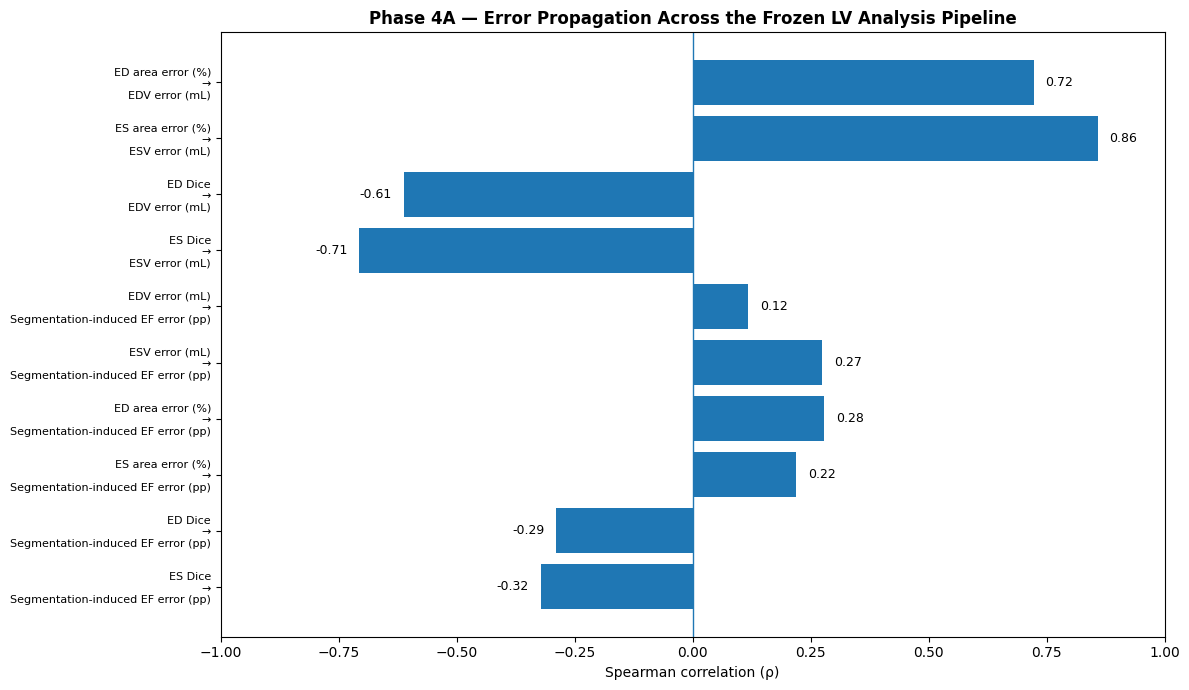

Saved: /content/drive/MyDrive/CAMUS_FINAL/phase4_robustness/phase4A_error_propagation/figures/phase4A_error_propagation_correlations.png


In [ ]:
# ================================================================
# PHASE 4A — CELL 16
# ERROR-PROPAGATION CORRELATION FIGURE
# ================================================================

import matplotlib.pyplot as plt


plot_df = phase4A_correlation_df.copy()

plot_df["relationship"] = (
    plot_df["predictor"]
    + "\n→\n"
    + plot_df["outcome"]
)


fig, ax = plt.subplots(
    figsize=(12, 7)
)


bars = ax.barh(
    np.arange(len(plot_df)),
    plot_df["spearman_rho"]
)


ax.set_yticks(
    np.arange(len(plot_df))
)

ax.set_yticklabels(
    plot_df["relationship"],
    fontsize=8
)


ax.axvline(
    0,
    linewidth=1
)


ax.set_xlabel(
    "Spearman correlation (ρ)"
)

ax.set_title(
    "Phase 4A — Error Propagation Across the Frozen LV Analysis Pipeline",
    fontweight="bold"
)


ax.set_xlim(
    -1,
    1
)


# ---------------------------------------------------------------
# VALUE LABELS
# ---------------------------------------------------------------

for i, rho in enumerate(
    plot_df["spearman_rho"]
):

    if rho >= 0:

        x_position = rho + 0.025
        alignment = "left"

    else:

        x_position = rho - 0.025
        alignment = "right"


    ax.text(
        x_position,
        i,
        f"{rho:.2f}",
        va="center",
        ha=alignment,
        fontsize=9
    )


ax.invert_yaxis()

plt.tight_layout()


CORRELATION_FIGURE_PATH = (
    PHASE4A_FIGURES_DIR
    / "phase4A_error_propagation_correlations.png"
)


plt.savefig(
    CORRELATION_FIGURE_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


print(
    "Saved:",
    CORRELATION_FIGURE_PATH
)

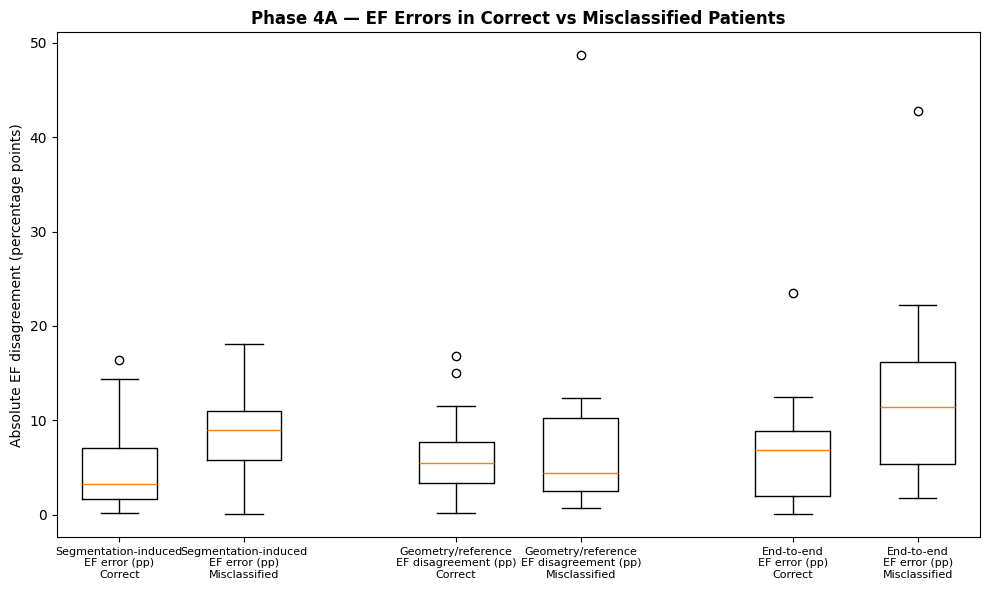

Saved: /content/drive/MyDrive/CAMUS_FINAL/phase4_robustness/phase4A_error_propagation/figures/phase4A_correct_vs_misclassified_EF_errors.png


In [ ]:
# ================================================================
# PHASE 4A — CELL 17
# CORRECT VS MISCLASSIFIED — DOWNSTREAM ERROR FIGURE
# ================================================================

comparison_plot_variables = [

    (
        "Segmentation-induced\nEF error (pp)",
        "segmentation_induced_EF_abs_error_pp"
    ),

    (
        "Geometry/reference\nEF disagreement (pp)",
        "geometry_reference_EF_abs_error_pp"
    ),

    (
        "End-to-end\nEF error (pp)",
        "end_to_end_EF_abs_error_pp"
    )
]


plot_records = []


for label, column in comparison_plot_variables:

    for _, row in phase4A_df.iterrows():

        plot_records.append({

            "metric": label,

            "classification":
                (
                    "Correct"
                    if row["classification_error"] == 0
                    else "Misclassified"
                ),

            "value":
                row[column]
        })


comparison_plot_df = pd.DataFrame(
    plot_records
)


fig, ax = plt.subplots(
    figsize=(10, 6)
)


positions = []
data = []
labels = []

current_position = 1


for metric_name, _ in comparison_plot_variables:

    for classification in [
        "Correct",
        "Misclassified"
    ]:

        values = comparison_plot_df[
            (
                comparison_plot_df["metric"]
                == metric_name
            )
            &
            (
                comparison_plot_df["classification"]
                == classification
            )
        ]["value"].to_numpy()


        data.append(
            values
        )

        positions.append(
            current_position
        )

        labels.append(
            f"{metric_name}\n{classification}"
        )

        current_position += 1


    current_position += 0.7


ax.boxplot(
    data,
    positions=positions,
    widths=0.6,
    showfliers=True
)


ax.set_xticks(
    positions
)

ax.set_xticklabels(
    labels,
    fontsize=8
)


ax.set_ylabel(
    "Absolute EF disagreement (percentage points)"
)


ax.set_title(
    "Phase 4A — EF Errors in Correct vs Misclassified Patients",
    fontweight="bold"
)


plt.tight_layout()


CLASSIFICATION_ERROR_FIGURE_PATH = (
    PHASE4A_FIGURES_DIR
    / "phase4A_correct_vs_misclassified_EF_errors.png"
)


plt.savefig(
    CLASSIFICATION_ERROR_FIGURE_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


print(
    "Saved:",
    CLASSIFICATION_ERROR_FIGURE_PATH
)

/tmp/ipykernel_843/3002469191.py:21: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(


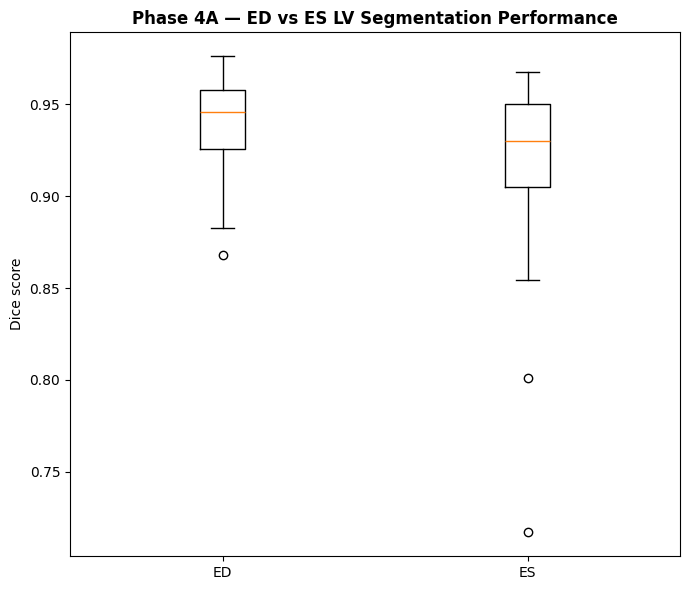

Saved: /content/drive/MyDrive/CAMUS_FINAL/phase4_robustness/phase4A_error_propagation/figures/phase4A_ED_vs_ES_dice.png


/tmp/ipykernel_843/3002469191.py:85: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(


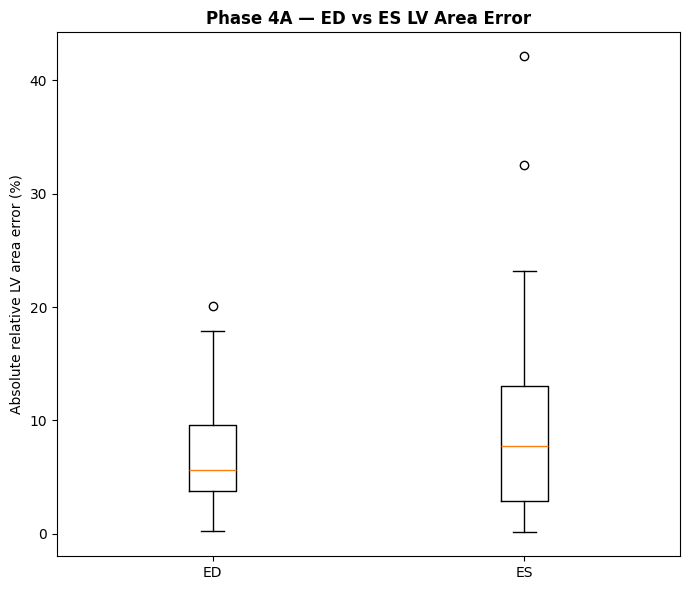

Saved: /content/drive/MyDrive/CAMUS_FINAL/phase4_robustness/phase4A_error_propagation/figures/phase4A_ED_vs_ES_area_error.png


In [ ]:
# ================================================================
# PHASE 4A — CELL 18
# ED VS ES SEGMENTATION VULNERABILITY
# ================================================================

# ---------------------------------------------------------------
# DICE
# ---------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(7, 6)
)


dice_data = [
    phase4A_df["ED_dice"].to_numpy(),
    phase4A_df["ES_dice"].to_numpy()
]


ax.boxplot(
    dice_data,
    labels=[
        "ED",
        "ES"
    ],
    showfliers=True
)


ax.set_ylabel(
    "Dice score"
)

ax.set_title(
    "Phase 4A — ED vs ES LV Segmentation Performance",
    fontweight="bold"
)


plt.tight_layout()


DICE_FIGURE_PATH = (
    PHASE4A_FIGURES_DIR
    / "phase4A_ED_vs_ES_dice.png"
)


plt.savefig(
    DICE_FIGURE_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


print(
    "Saved:",
    DICE_FIGURE_PATH
)


# ---------------------------------------------------------------
# AREA ERROR
# ---------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(7, 6)
)


area_error_data = [
    phase4A_df[
        "ED_area_abs_relative_error_pct"
    ].to_numpy(),

    phase4A_df[
        "ES_area_abs_relative_error_pct"
    ].to_numpy()
]


ax.boxplot(
    area_error_data,
    labels=[
        "ED",
        "ES"
    ],
    showfliers=True
)


ax.set_ylabel(
    "Absolute relative LV area error (%)"
)

ax.set_title(
    "Phase 4A — ED vs ES LV Area Error",
    fontweight="bold"
)


plt.tight_layout()


AREA_FIGURE_PATH = (
    PHASE4A_FIGURES_DIR
    / "phase4A_ED_vs_ES_area_error.png"
)


plt.savefig(
    AREA_FIGURE_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


print(
    "Saved:",
    AREA_FIGURE_PATH
)

In [ ]:
# ================================================================
# PHASE 4A — CELL 19
# PATIENT-LEVEL ERROR CHAIN RANKING
# ================================================================

error_chain_columns = [

    "patient_id",
    "image_quality",

    "ED_dice",
    "ES_dice",

    "ED_area_abs_relative_error_pct",
    "ES_area_abs_relative_error_pct",

    "EDV_abs_error_ml",
    "ESV_abs_error_ml",

    "reference_EF_pct",
    "GT_EF_pct",
    "PRED_EF_pct",

    "geometry_reference_EF_abs_error_pp",
    "segmentation_induced_EF_abs_error_pp",
    "end_to_end_EF_abs_error_pp",

    "reference_EF_class",
    "learned_prediction",
    "classification_error",

    "model_confidence"
]


phase4A_ranked_df = (
    phase4A_df[
        error_chain_columns
    ]
    .sort_values(
        "segmentation_induced_EF_abs_error_pp",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)


phase4A_ranked_df.insert(
    0,
    "segmentation_EF_error_rank",
    np.arange(
        1,
        len(phase4A_ranked_df) + 1
    )
)


print("=" * 80)
print("TOP 10 SEGMENTATION-INDUCED EF ERROR CASES")
print("=" * 80)


display(
    phase4A_ranked_df.head(10)
)


RANKING_PATH = (
    PHASE4A_TABLES_DIR
    / "phase4A_patient_error_chain_ranking.csv"
)


phase4A_ranked_df.to_csv(
    RANKING_PATH,
    index=False
)


print(
    "\nSaved:",
    RANKING_PATH
)

TOP 10 SEGMENTATION-INDUCED EF ERROR CASES


,segmentation_EF_error_rank,patient_id,image_quality,ED_dice,ES_dice,ED_area_abs_relative_error_pct,ES_area_abs_relative_error_pct,EDV_abs_error_ml,ESV_abs_error_ml,reference_EF_pct,GT_EF_pct,PRED_EF_pct,geometry_reference_EF_abs_error_pp,segmentation_induced_EF_abs_error_pp,end_to_end_EF_abs_error_pp,reference_EF_class,learned_prediction,classification_error,model_confidence
0,1,patient0358,Poor,0.910433,0.943987,11.982420,1.252539,16.511070,2.179947,44.0,47.491380,29.435975,3.491380,18.055405,14.564025,Intermediate_EF,Lower_EF,1,0.888209
1,2,patient0367,Medium,0.944141,0.890147,7.664042,17.450300,6.751065,5.768357,62.0,65.105917,47.681849,3.105917,17.424068,14.318151,Higher_EF,Intermediate_EF,1,0.570224
2,3,patient0391,Good,0.924814,0.892653,12.489746,23.198259,6.754818,10.625558,35.0,39.868425,23.478531,4.868425,16.389894,11.521469,Lower_EF,Lower_EF,0,0.910782
3,4,patient0014,Good,0.904204,0.716995,15.928464,42.148518,17.152771,14.019124,50.0,59.130401,73.481698,9.130401,14.351298,23.481698,Higher_EF,Higher_EF,0,0.931696
4,5,patient0082,Good,0.948325,0.907397,1.767330,15.078083,0.301504,10.108496,54.0,48.530715,60.826023,5.469285,12.295308,6.826023,Higher_EF,Higher_EF,0,0.702656
5,6,patient0302,Good,0.948284,0.935673,8.871111,0.800641,18.439551,4.784402,49.0,53.740191,41.512318,4.740191,12.227873,7.487682,Intermediate_EF,Lower_EF,1,0.580271
6,7,patient0328,Poor,0.867799,0.946314,13.026304,1.121969,18.147690,2.591154,25.0,35.672906,47.230385,10.672906,11.557479,22.230385,Lower_EF,Intermediate_EF,1,0.469398
7,8,patient0120,Poor,0.933670,0.932186,4.599012,12.023177,6.690357,14.027296,30.0,27.472417,38.762478,2.527583,11.290061,8.762478,Lower_EF,Lower_EF,0,0.708200
8,9,patient0465,Medium,0.947320,0.876081,9.242126,21.765650,22.613290,25.743731,45.0,53.044190,63.436843,8.044190,10.392653,18.436843,Intermediate_EF,Higher_EF,1,0.773126
9,10,patient0347,Medium,0.943943,0.961398,7.458466,3.288490,17.278102,2.076082,54.0,56.136496,66.141143,2.136496,10.004647,12.141143,Higher_EF,Higher_EF,0,0.878486



Saved: /content/drive/MyDrive/CAMUS_FINAL/phase4_robustness/phase4A_error_propagation/tables/phase4A_patient_error_chain_ranking.csv


In [ ]:
# ================================================================
# PHASE 4A — CELL 20
# SAVE PHASE 4A RESULTS SUMMARY
# ================================================================

phase4A_summary = {

    "phase":
        "Phase 4A",

    "title":
        "End-to-End Error Propagation Analysis",

    "analysis_type":
        "Descriptive/exploratory analysis of frozen evaluation outputs",

    "n_patients":
        int(len(phase4A_df)),

    "classification": {

        "correct":
            int(
                (
                    phase4A_df[
                        "classification_error"
                    ] == 0
                ).sum()
            ),

        "incorrect":
            int(
                phase4A_df[
                    "classification_error"
                ].sum()
            )
    },

    "mean_absolute_EF_errors_pp": {

        "geometry_reference":
            float(
                phase4A_df[
                    "geometry_reference_EF_abs_error_pp"
                ].mean()
            ),

        "segmentation_induced":
            float(
                phase4A_df[
                    "segmentation_induced_EF_abs_error_pp"
                ].mean()
            ),

        "end_to_end":
            float(
                phase4A_df[
                    "end_to_end_EF_abs_error_pp"
                ].mean()
            )
    },

    "key_correlations": {

        "ED_area_error_to_EDV_error":
            float(
                phase4A_correlation_df.loc[
                    (
                        phase4A_correlation_df[
                            "predictor"
                        ]
                        == "ED area error (%)"
                    )
                    &
                    (
                        phase4A_correlation_df[
                            "outcome"
                        ]
                        == "EDV error (mL)"
                    ),
                    "spearman_rho"
                ].iloc[0]
            ),

        "ES_area_error_to_ESV_error":
            float(
                phase4A_correlation_df.loc[
                    (
                        phase4A_correlation_df[
                            "predictor"
                        ]
                        == "ES area error (%)"
                    )
                    &
                    (
                        phase4A_correlation_df[
                            "outcome"
                        ]
                        == "ESV error (mL)"
                    ),
                    "spearman_rho"
                ].iloc[0]
            )
    },

    "classification_group_medians": {

        "segmentation_induced_EF_error_correct":
            float(
                correct_df[
                    "segmentation_induced_EF_abs_error_pp"
                ].median()
            ),

        "segmentation_induced_EF_error_incorrect":
            float(
                incorrect_df[
                    "segmentation_induced_EF_abs_error_pp"
                ].median()
            ),

        "end_to_end_EF_error_correct":
            float(
                correct_df[
                    "end_to_end_EF_abs_error_pp"
                ].median()
            ),

        "end_to_end_EF_error_incorrect":
            float(
                incorrect_df[
                    "end_to_end_EF_abs_error_pp"
                ].median()
            )
    },

    "protocol_notes": [

        "No model training or retraining performed.",

        "No segmentation, geometry, EF, or classification thresholds modified.",

        "All analyses use the frozen 50-patient evaluation outputs.",

        "Associations are exploratory and do not establish causation.",

        "Multiple exploratory statistical comparisons were performed; "
        "individual p-values are not treated as confirmatory evidence.",

        "Absolute EF error components are not assumed to be additive."
    ]
}


PHASE4A_SUMMARY_PATH = (
    PHASE4A_CONFIGS_DIR
    / "phase4A_results_summary.json"
)


with open(
    PHASE4A_SUMMARY_PATH,
    "w"
) as file:

    json.dump(
        phase4A_summary,
        file,
        indent=4
    )


print("=" * 80)
print("PHASE 4A RESULTS SUMMARY SAVED")
print("=" * 80)

print(
    "\nPath:"
)

print(
    PHASE4A_SUMMARY_PATH
)

print(
    "\n✓ Phase 4A major findings recorded."
)

PHASE 4A RESULTS SUMMARY SAVED

Path:
/content/drive/MyDrive/CAMUS_FINAL/phase4_robustness/phase4A_error_propagation/configs/phase4A_results_summary.json

✓ Phase 4A major findings recorded.


In [ ]:
# ================================================================
# PHASE 4A — CELL 21
# EF-BAND BOUNDARY PROXIMITY
# ================================================================

phase4A_df = phase4A_df.copy()


def distance_to_nearest_EF_boundary(reference_ef):

    return min(
        abs(reference_ef - 40.0),
        abs(reference_ef - 50.0)
    )


phase4A_df[
    "distance_to_nearest_EF_boundary_pp"
] = phase4A_df[
    "reference_EF_pct"
].apply(
    distance_to_nearest_EF_boundary
)


# ---------------------------------------------------------------
# DESCRIPTIVE GROUPS ONLY
# These are NOT new classification thresholds.
# ---------------------------------------------------------------

def boundary_proximity_group(distance):

    if distance <= 2:
        return "≤2 pp"

    elif distance <= 5:
        return ">2–5 pp"

    else:
        return ">5 pp"


phase4A_df[
    "boundary_proximity_group"
] = phase4A_df[
    "distance_to_nearest_EF_boundary_pp"
].apply(
    boundary_proximity_group
)


print("=" * 80)
print("EF-BAND BOUNDARY PROXIMITY")
print("=" * 80)

print(
    "\nDistance summary:"
)

print(
    phase4A_df[
        "distance_to_nearest_EF_boundary_pp"
    ].describe()
)


print(
    "\nDescriptive proximity groups:"
)

print(
    phase4A_df[
        "boundary_proximity_group"
    ].value_counts()
)


print(
    "\nNOTE:"
)

print(
    "The ≤2 pp and ≤5 pp values are descriptive bins only."
)

print(
    "They are not optimized thresholds and will not alter "
    "the frozen classifier."
)

EF-BAND BOUNDARY PROXIMITY

Distance summary:
count    50.000000
mean      6.540000
std       5.782486
min       0.000000
25%       2.250000
50%       5.000000
75%       9.000000
max      27.000000
Name: distance_to_nearest_EF_boundary_pp, dtype: float64

Descriptive proximity groups:
boundary_proximity_group
>5 pp      21
>2–5 pp    16
≤2 pp      13
Name: count, dtype: int64

NOTE:
The ≤2 pp and ≤5 pp values are descriptive bins only.
They are not optimized thresholds and will not alter the frozen classifier.


In [ ]:
# ================================================================
# PHASE 4A — CELL 22
# BOUNDARY PROXIMITY VS CLASSIFICATION OUTCOME
# ================================================================

from scipy.stats import mannwhitneyu


correct_boundary = phase4A_df.loc[
    phase4A_df["classification_error"] == 0,
    "distance_to_nearest_EF_boundary_pp"
]


incorrect_boundary = phase4A_df.loc[
    phase4A_df["classification_error"] == 1,
    "distance_to_nearest_EF_boundary_pp"
]


u_statistic, boundary_p_value = mannwhitneyu(
    correct_boundary,
    incorrect_boundary,
    alternative="two-sided"
)


print("=" * 80)
print("BOUNDARY PROXIMITY — CORRECT VS MISCLASSIFIED")
print("=" * 80)

print(
    f"\nCorrect patients (n={len(correct_boundary)}):"
)

print(
    f"Median distance = {correct_boundary.median():.4f} pp"
)


print(
    f"\nMisclassified patients (n={len(incorrect_boundary)}):"
)

print(
    f"Median distance = {incorrect_boundary.median():.4f} pp"
)


print(
    "\nMedian difference "
    "(incorrect - correct):"
)

print(
    f"{incorrect_boundary.median() - correct_boundary.median():.4f} pp"
)


print(
    "\nMann–Whitney U:",
    f"{u_statistic:.4f}"
)

print(
    "Exploratory p-value:",
    f"{boundary_p_value:.6f}"
)


boundary_group_summary = (
    phase4A_df
    .groupby(
        "boundary_proximity_group",
        observed=True
    )
    .agg(
        n=("patient_id", "count"),
        misclassified=("classification_error", "sum")
    )
    .reset_index()
)


boundary_group_summary[
    "misclassification_rate_pct"
] = (
    boundary_group_summary[
        "misclassified"
    ]
    /
    boundary_group_summary[
        "n"
    ]
    * 100
)


print(
    "\nDescriptive misclassification rates:"
)

display(
    boundary_group_summary
)


print(
    "\nInterpret cautiously: subgroup sizes may be small and "
    "these bins were not predefined as inferential thresholds."
)

BOUNDARY PROXIMITY — CORRECT VS MISCLASSIFIED

Correct patients (n=35):
Median distance = 5.0000 pp

Misclassified patients (n=15):
Median distance = 4.0000 pp

Median difference (incorrect - correct):
-1.0000 pp

Mann–Whitney U: 328.0000
Exploratory p-value: 0.167141

Descriptive misclassification rates:


,boundary_proximity_group,n,misclassified,misclassification_rate_pct
0,>2–5 pp,16,5,31.250000
1,>5 pp,21,4,19.047619
2,≤2 pp,13,6,46.153846



Interpret cautiously: subgroup sizes may be small and these bins were not predefined as inferential thresholds.


In [ ]:
# ================================================================
# PHASE 4A — CELL 23
# EF ERROR RELATIVE TO BOUNDARY PROXIMITY
# ================================================================

# Avoid division by zero for patients exactly on a boundary.
# Exact-boundary cases are retained but ratio is undefined.
distance = phase4A_df[
    "distance_to_nearest_EF_boundary_pp"
]


phase4A_df[
    "end_to_end_error_to_boundary_ratio"
] = np.where(
    distance > 0,
    phase4A_df[
        "end_to_end_EF_abs_error_pp"
    ] / distance,
    np.nan
)


phase4A_df[
    "segmentation_error_to_boundary_ratio"
] = np.where(
    distance > 0,
    phase4A_df[
        "segmentation_induced_EF_abs_error_pp"
    ] / distance,
    np.nan
)


print("=" * 80)
print("ERROR MAGNITUDE RELATIVE TO EF-BAND BOUNDARY")
print("=" * 80)


ratio_summary = (
    phase4A_df
    .groupby(
        "classification_error"
    )
    .agg(

        n=(
            "patient_id",
            "count"
        ),

        median_boundary_distance_pp=(
            "distance_to_nearest_EF_boundary_pp",
            "median"
        ),

        median_segmentation_EF_error_pp=(
            "segmentation_induced_EF_abs_error_pp",
            "median"
        ),

        median_end_to_end_EF_error_pp=(
            "end_to_end_EF_abs_error_pp",
            "median"
        ),

        median_segmentation_error_boundary_ratio=(
            "segmentation_error_to_boundary_ratio",
            "median"
        ),

        median_end_to_end_error_boundary_ratio=(
            "end_to_end_error_to_boundary_ratio",
            "median"
        )
    )
    .reset_index()
)


ratio_summary[
    "classification_outcome"
] = ratio_summary[
    "classification_error"
].map({
    0: "Correct",
    1: "Misclassified"
})


ratio_summary = ratio_summary[[
    "classification_outcome",
    "n",
    "median_boundary_distance_pp",
    "median_segmentation_EF_error_pp",
    "median_end_to_end_EF_error_pp",
    "median_segmentation_error_boundary_ratio",
    "median_end_to_end_error_boundary_ratio"
]]


display(
    ratio_summary.round(4)
)


print(
    "\nIMPORTANT:"
)

print(
    "The error-to-boundary ratio is a descriptive diagnostic "
    "quantity, not a validated risk score."
)

ERROR MAGNITUDE RELATIVE TO EF-BAND BOUNDARY


,classification_outcome,n,median_boundary_distance_pp,median_segmentation_EF_error_pp,median_end_to_end_EF_error_pp,median_segmentation_error_boundary_ratio,median_end_to_end_error_boundary_ratio
0,Correct,35,5.0,3.2347,6.8260,0.4386,0.7943
1,Misclassified,15,4.0,8.9178,11.4571,2.1179,2.7008



IMPORTANT:
The error-to-boundary ratio is a descriptive diagnostic quantity, not a validated risk score.


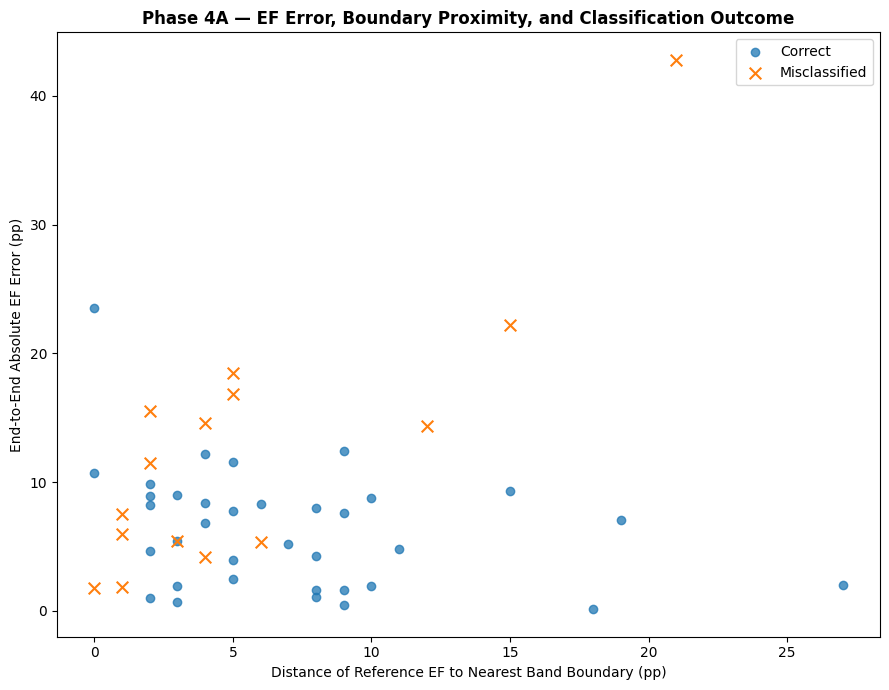

Saved: /content/drive/MyDrive/CAMUS_FINAL/phase4_robustness/phase4A_error_propagation/figures/phase4A_EF_boundary_sensitivity.png


In [ ]:
# ================================================================
# PHASE 4A — CELL 24
# BOUNDARY SENSITIVITY FIGURE
# ================================================================

import matplotlib.pyplot as plt


fig, ax = plt.subplots(
    figsize=(9, 7)
)


correct_cases = phase4A_df[
    phase4A_df[
        "classification_error"
    ] == 0
]


incorrect_cases = phase4A_df[
    phase4A_df[
        "classification_error"
    ] == 1
]


ax.scatter(
    correct_cases[
        "distance_to_nearest_EF_boundary_pp"
    ],
    correct_cases[
        "end_to_end_EF_abs_error_pp"
    ],
    alpha=0.75,
    label="Correct"
)


ax.scatter(
    incorrect_cases[
        "distance_to_nearest_EF_boundary_pp"
    ],
    incorrect_cases[
        "end_to_end_EF_abs_error_pp"
    ],
    marker="x",
    s=70,
    label="Misclassified"
)


ax.set_xlabel(
    "Distance of Reference EF to Nearest Band Boundary (pp)"
)

ax.set_ylabel(
    "End-to-End Absolute EF Error (pp)"
)


ax.set_title(
    "Phase 4A — EF Error, Boundary Proximity, and Classification Outcome",
    fontweight="bold"
)


ax.legend()


plt.tight_layout()


BOUNDARY_FIGURE_PATH = (
    PHASE4A_FIGURES_DIR
    / "phase4A_EF_boundary_sensitivity.png"
)


plt.savefig(
    BOUNDARY_FIGURE_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


print(
    "Saved:",
    BOUNDARY_FIGURE_PATH
)

In [ ]:
# ================================================================
# PHASE 4A — CELL 25
# SAVE BOUNDARY-SENSITIVITY ANALYSIS
# ================================================================

BOUNDARY_PATIENT_PATH = (
    PHASE4A_TABLES_DIR
    / "phase4A_boundary_sensitivity_patient_level.csv"
)

BOUNDARY_GROUP_PATH = (
    PHASE4A_TABLES_DIR
    / "phase4A_boundary_proximity_groups.csv"
)

BOUNDARY_RATIO_PATH = (
    PHASE4A_TABLES_DIR
    / "phase4A_boundary_error_ratio_summary.csv"
)


boundary_patient_columns = [

    "patient_id",

    "reference_EF_pct",
    "reference_EF_class",

    "PRED_EF_pct",
    "learned_prediction",

    "distance_to_nearest_EF_boundary_pp",
    "boundary_proximity_group",

    "segmentation_induced_EF_abs_error_pp",
    "end_to_end_EF_abs_error_pp",

    "segmentation_error_to_boundary_ratio",
    "end_to_end_error_to_boundary_ratio",

    "classification_error",
    "model_confidence"
]


phase4A_df[
    boundary_patient_columns
].to_csv(
    BOUNDARY_PATIENT_PATH,
    index=False
)


boundary_group_summary.to_csv(
    BOUNDARY_GROUP_PATH,
    index=False
)


ratio_summary.to_csv(
    BOUNDARY_RATIO_PATH,
    index=False
)


print("=" * 80)
print("BOUNDARY-SENSITIVITY OUTPUTS SAVED")
print("=" * 80)

print("\n1.", BOUNDARY_PATIENT_PATH)
print("2.", BOUNDARY_GROUP_PATH)
print("3.", BOUNDARY_RATIO_PATH)

print(
    "\n✓ Boundary analysis saved."
)

BOUNDARY-SENSITIVITY OUTPUTS SAVED

1. /content/drive/MyDrive/CAMUS_FINAL/phase4_robustness/phase4A_error_propagation/tables/phase4A_boundary_sensitivity_patient_level.csv
2. /content/drive/MyDrive/CAMUS_FINAL/phase4_robustness/phase4A_error_propagation/tables/phase4A_boundary_proximity_groups.csv
3. /content/drive/MyDrive/CAMUS_FINAL/phase4_robustness/phase4A_error_propagation/tables/phase4A_boundary_error_ratio_summary.csv

✓ Boundary analysis saved.


In [ ]:
# ================================================================
# PHASE 4A — CELL 26
# FINAL SCIENTIFIC INTERPRETATION
# ================================================================

phase4A_interpretation = {

    "phase":
        "Phase 4A",

    "title":
        "End-to-End Error Propagation Analysis",

    "status":
        "COMPLETE_AND_FROZEN",

    "evaluation_population":
        "Frozen 50-patient evaluation set",

    "main_findings": [

        (
            "Segmentation disagreement propagated strongly into "
            "corresponding ventricular volume disagreement. "
            "ED area error was strongly associated with EDV error "
            "(Spearman rho = 0.7228), while ES area error was "
            "strongly associated with ESV error "
            "(rho = 0.8580)."
        ),

        (
            "Poorer segmentation overlap was also associated with "
            "larger volume disagreement: ED Dice versus EDV error "
            "rho = -0.6122 and ES Dice versus ESV error "
            "rho = -0.7063."
        ),

        (
            "Propagation from individual EDV/ESV absolute errors "
            "to segmentation-induced EF error was substantially "
            "weaker. EDV error showed rho = 0.1179 and ESV error "
            "rho = 0.2748 with segmentation-induced EF error. "
            "This is consistent with EF depending jointly on EDV "
            "and ESV rather than on either measurement alone."
        ),

        (
            "Patients misclassified by the frozen EF-band classifier "
            "had substantially larger median segmentation-induced "
            "EF disagreement than correctly classified patients "
            "(8.9178 pp versus 3.2347 pp)."
        ),

        (
            "Median end-to-end EF disagreement was also larger in "
            "misclassified than correctly classified patients "
            "(11.4571 pp versus 6.8260 pp)."
        ),

        (
            "Geometry/reference EF disagreement alone did not show "
            "the same pattern: median disagreement was 4.4390 pp "
            "in misclassified patients and 5.4885 pp in correctly "
            "classified patients."
        ),

        (
            "ES segmentation showed lower median Dice than ED "
            "(0.9300 versus 0.9457) and larger median relative "
            "area error (7.7022% versus 5.5976%)."
        ),

        (
            "Despite greater relative ES segmentation difficulty, "
            "median absolute volume error was larger for EDV than "
            "ESV (7.8553 mL versus 5.3671 mL). Absolute and relative "
            "errors therefore describe different aspects of the "
            "error pathway."
        ),

        (
            "Reference-EF distance to the nearest 40% or 50% band "
            "boundary alone did not clearly separate correct and "
            "misclassified patients: medians were 5.0 pp and "
            "4.0 pp respectively (exploratory p = 0.1671)."
        ),

        (
            "Descriptively, misclassification occurred in 46.15% "
            "of patients within 2 pp of a band boundary, compared "
            "with 19.05% among patients more than 5 pp away. "
            "These subgroup sizes are small and the bins are "
            "descriptive rather than validated thresholds."
        ),

        (
            "The post-hoc end-to-end EF-error-to-boundary ratio "
            "had a median of 0.7943 in correctly classified cases "
            "and 2.7008 in misclassified cases. This supports the "
            "concept that classification vulnerability may depend "
            "on both measurement disagreement and boundary "
            "proximity, but the ratio is not a validated reliability "
            "score or decision threshold."
        )
    ],

    "interpretation": (
        "The frozen pipeline exhibits clear propagation of LV "
        "segmentation disagreement into quantitative volume "
        "measurements. Propagation into EF and final EF-band "
        "classification is more complex because EF depends jointly "
        "on EDV and ESV and because discrete classification also "
        "depends on the location of the resulting estimate relative "
        "to the predefined EF-band boundaries. Classification "
        "failure therefore cannot be explained by segmentation "
        "quality or boundary proximity alone."
    ),

    "limitations": [

        (
            "The analysis uses only the frozen 50-patient "
            "evaluation set."
        ),

        (
            "The evaluation set had historical pilot exposure and "
            "is not described as a pristine external test set."
        ),

        (
            "Statistical analyses are exploratory and multiple "
            "comparisons were performed."
        ),

        (
            "Associations do not establish causal relationships."
        ),

        (
            "Absolute error components are not additive."
        ),

        (
            "Boundary proximity groups and error-to-boundary ratios "
            "were descriptive post-hoc analyses and were not used "
            "to modify the classifier or establish operational "
            "thresholds."
        )
    ],

    "pipeline_changes_after_analysis":
        False
}


PHASE4A_FINAL_RECORD_PATH = (
    PHASE4A_CONFIGS_DIR
    / "phase4A_final_record.json"
)


with open(
    PHASE4A_FINAL_RECORD_PATH,
    "w"
) as file:

    json.dump(
        phase4A_interpretation,
        file,
        indent=4
    )


print("=" * 80)
print("PHASE 4A — FINAL RECORD")
print("=" * 80)

print("\nStatus:")
print(
    phase4A_interpretation[
        "status"
    ]
)

print("\nSaved:")
print(
    PHASE4A_FINAL_RECORD_PATH
)

print(
    "\n✓ Phase 4A interpretation recorded."
)
print(
    "✓ No pipeline changes made."
)

PHASE 4A — FINAL RECORD

Status:
COMPLETE_AND_FROZEN

Saved:
/content/drive/MyDrive/CAMUS_FINAL/phase4_robustness/phase4A_error_propagation/configs/phase4A_final_record.json

✓ Phase 4A interpretation recorded.
✓ No pipeline changes made.


In [ ]:
# ================================================================
# PHASE 4A — CELL 27
# COMPLETION MARKER
# ================================================================

required_phase4A_outputs = [

    PHASE4A_CANONICAL_PATH,

    CORRELATION_PATH,

    CLASSIFICATION_COMPARISON_PATH,

    ED_ES_PATH,

    RANKING_PATH,

    BOUNDARY_PATIENT_PATH,

    BOUNDARY_GROUP_PATH,

    BOUNDARY_RATIO_PATH,

    PHASE4A_SUMMARY_PATH,

    PHASE4A_FINAL_RECORD_PATH
]


print("=" * 80)
print("PHASE 4A — FINAL OUTPUT CHECK")
print("=" * 80)


all_present = True


for path in required_phase4A_outputs:

    exists = path.exists()

    print(
        f"{'✓' if exists else '✗'} "
        f"{path.name}"
    )

    if not exists:
        all_present = False


assert all_present, (
    "One or more required Phase 4A outputs are missing."
)


completion_record = {

    "phase":
        "Phase 4A",

    "title":
        "End-to-End Error Propagation Analysis",

    "status":
        "COMPLETE_AND_FROZEN",

    "n_patients":
        50,

    "model_training":
        False,

    "model_selection":
        False,

    "threshold_tuning":
        False,

    "post_evaluation_pipeline_modification":
        False,

    "next_phase":
        "Phase 4B — Confidence and Uncertainty Analysis"
}


PHASE4A_COMPLETION_PATH = (
    PHASE4A_DIR
    / "PHASE4A_COMPLETE.json"
)


with open(
    PHASE4A_COMPLETION_PATH,
    "w"
) as file:

    json.dump(
        completion_record,
        file,
        indent=4
    )


print("\n" + "=" * 80)
print("PHASE 4A COMPLETE AND FROZEN")
print("=" * 80)

print(
    "\nCompletion marker:"
)

print(
    PHASE4A_COMPLETION_PATH
)

print(
    "\nNo further tuning or methodological changes "
    "will be made from Phase 4A evaluation results."
)

print(
    "\nNext: Phase 4B — Confidence and Uncertainty Analysis"
)

PHASE 4A — FINAL OUTPUT CHECK
✓ phase4A_canonical_patient_error_chain.csv
✓ phase4A_error_propagation_correlations.csv
✓ phase4A_correct_vs_misclassified.csv
✓ phase4A_ED_vs_ES_comparison.csv
✓ phase4A_patient_error_chain_ranking.csv
✓ phase4A_boundary_sensitivity_patient_level.csv
✓ phase4A_boundary_proximity_groups.csv
✓ phase4A_boundary_error_ratio_summary.csv
✓ phase4A_results_summary.json
✓ phase4A_final_record.json

PHASE 4A COMPLETE AND FROZEN

Completion marker:
/content/drive/MyDrive/CAMUS_FINAL/phase4_robustness/phase4A_error_propagation/PHASE4A_COMPLETE.json

No further tuning or methodological changes will be made from Phase 4A evaluation results.

Next: Phase 4B — Confidence and Uncertainty Analysis
